## **KECERDASAN ARTIFISIAL UNTUK GEOFISIKA**
### **RECIPE GEOFISIKA: ANALISIS DATA SEISMIK REFRAKSI**
**NAMA:** Sabastian Clifford Malolok

**NIM:** H061251021 

**KELAS:** A

<hr>

#### **Recipe ID: GEO-SEIS-002**
**Bidang:** Geofisika near-surface  
**Topik:** Analisis kurva waktu tempuh gelombang seismik refraksi untuk mengestimasi kecepatan lapisan dan kedalaman antarmuka.

**Petunjuk:** Jalankan sel kode secara berurutan dari atas ke bawah. Notebook menggunakan data sintetik sehingga dapat langsung dijalankan tanpa file lapangan.

**Catatan:** Data yang digunakan adalah data simulasi untuk pembelajaran, bukan hasil pengukuran lapangan.

### **1. Problem — Permasalahan**

Survei seismik refraksi mengukur waktu tempuh gelombang dari sumber menuju geofon pada jarak tertentu. Perubahan kemiringan kurva waktu tempuh terhadap jarak dapat menunjukkan perbedaan kecepatan gelombang pada lapisan bawah permukaan.

Tujuan analisis:
1. Memeriksa kelengkapan dan kualitas data jarak serta waktu tempuh.
2. Membuat grafik waktu tempuh terhadap jarak.
3. Memisahkan gelombang langsung dan gelombang refraksi dengan regresi linear sederhana.
4. Mengestimasi kecepatan lapisan pertama dan lapisan refraktor.
5. Mengestimasi kedalaman antarmuka menggunakan metode intercept-time untuk model dua lapisan.
6. Mengekspor tabel dan ringkasan hasil ke CSV.

**Batasan:** Interpretasi menggunakan model dua lapisan sederhana dengan asumsi lapisan bawah memiliki kecepatan lebih tinggi daripada lapisan atas dan antarmuka relatif datar.

### **2. Minimal Theory — Teori Singkat**

Waktu tempuh gelombang langsung pada lapisan pertama dapat ditulis:

$$t_d = \frac{x}{v_1}$$

Untuk gelombang refraksi pada model dua lapisan:

$$t_r = t_i + \frac{x}{v_2}$$

Kemiringan grafik waktu-tempuh terhadap jarak adalah kebalikan kecepatan:

$$v = \frac{1}{m}$$

dengan $m$ adalah gradien regresi linear. Kedalaman antarmuka diperkirakan menggunakan waktu intersep $t_i$:

$$h = \frac{t_i v_1}{2\sqrt{1-(v_1/v_2)^2}}$$

Keterangan:
- $x$: jarak sumber–geofon (m)
- $t$: waktu tempuh (s)
- $v_1$: kecepatan lapisan atas (m/s)
- $v_2$: kecepatan lapisan bawah/refraktor (m/s)
- $t_i$: waktu intersep (s)
- $h$: estimasi kedalaman antarmuka (m)

Rumus kedalaman berlaku untuk model dua lapisan ideal dengan $v_2 > v_1$.

### **3. Persiapan — Library yang Digunakan**

Library digunakan untuk pengolahan data tabel, regresi linear, perhitungan numerik, dan visualisasi.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import linregress

print("Library berhasil diimpor.")

Library berhasil diimpor.


### **4. Prompt — Instruksi Analisis untuk AI**

*Analisis data seismik refraksi dengan memeriksa data jarak dan waktu tempuh, membuat grafik waktu-tempuh terhadap jarak, mengidentifikasi segmen gelombang langsung dan refraksi, menghitung kecepatan dari gradien regresi linear, mengestimasi kedalaman antarmuka menggunakan waktu intersep untuk model dua lapisan, serta menyimpan hasil ke CSV. Bedakan secara jelas data simulasi dan data lapangan.*

### **5. Code — Pengaturan Sumber Data**

Pilih `USE_SIMULATED_DATA = True` agar notebook langsung berjalan menggunakan data sintetik. Untuk data lapangan, ubah menjadi `False` dan siapkan file `data_seismik_refraksi.csv` dengan kolom `Distance_m` dan `Time_ms`.

In [ ]:
USE_SIMULATED_DATA = True

if USE_SIMULATED_DATA:
    # Data sintetik untuk model dua lapisan; waktu dalam milidetik
    distance = np.array([5, 10, 15, 20, 25, 30, 35, 40, 45, 50,
                         55, 60, 65, 70, 75, 80, 85, 90, 95, 100], dtype=float)
    v1_sim = 500.0
    v2_sim = 1500.0
    h_sim = 8.0
    ti_sim = (2 * h_sim * np.sqrt(1 - (v1_sim / v2_sim)**2)) / v1_sim
    tc = distance / v1_sim
    tr = ti_sim + distance / v2_sim
    # Gelombang pertama yang tiba
    time_s = np.minimum(tc, tr)
    rng = np.random.default_rng(24)
    time_ms = (time_s + rng.normal(0, 0.0008, len(distance))) * 1000
    df = pd.DataFrame({"Distance_m": distance, "Time_ms": time_ms})
else:
    df = pd.read_csv("data_seismik_refraksi.csv")

print("Sumber data:", "SIMULASI" if USE_SIMULATED_DATA else "FILE LAPANGAN")
display(df.head())

Sumber data: SIMULASI


,Distance_m,Time_ms
0,5.0,11.080598
1,10.0,20.274472
2,15.0,29.069608
3,20.0,39.850331
4,25.0,46.564984


### **6. Code — Pemeriksaan Dasar Data**

Memastikan kolom tersedia, nilai numerik, tidak kosong, serta jarak dan waktu bernilai positif.

In [ ]:
required = ["Distance_m", "Time_ms"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing}")

df = df[required].apply(pd.to_numeric, errors="coerce")
if df.isna().any().any():
    raise ValueError("Data memiliki nilai kosong atau non-numerik.")
if (df["Distance_m"] <= 0).any() or (df["Time_ms"] <= 0).any():
    raise ValueError("Jarak dan waktu tempuh harus bernilai positif.")
if df["Distance_m"].duplicated().any():
    raise ValueError("Terdapat jarak geofon duplikat; periksa data terlebih dahulu.")

df = df.sort_values("Distance_m").reset_index(drop=True)
print("Ukuran data:", df.shape)
print("\nNilai kosong per kolom:")
print(df.isna().sum())
display(df.describe())

Ukuran data: (20, 2)

Nilai kosong per kolom:
Distance_m    0
Time_ms       0
dtype: int64


,Distance_m,Time_ms
count,20.000000,20.000000
mean,52.500000,62.486442
std,29.580399,24.347094
min,5.000000,11.080598
25%,28.750000,49.132057
50%,52.500000,64.643322
75%,76.250000,82.137644
max,100.000000,97.183901


### **7. Code — Visualisasi Data Waktu Tempuh**

Grafik awal membantu melihat perubahan pola waktu tempuh terhadap jarak.

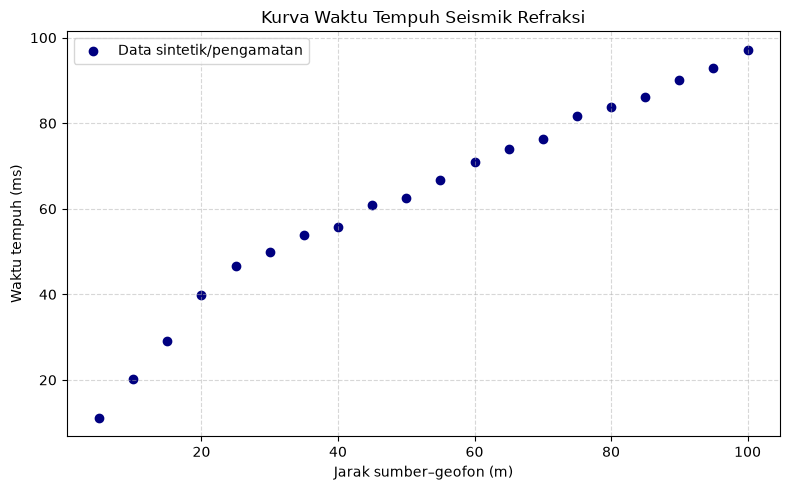

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Distance_m"], df["Time_ms"], color="navy", label="Data sintetik/pengamatan")
plt.xlabel("Jarak sumber–geofon (m)")
plt.ylabel("Waktu tempuh (ms)")
plt.title("Kurva Waktu Tempuh Seismik Refraksi")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### **8. Code — Regresi Linear dan Estimasi Kecepatan**

Untuk contoh data ini, titik berjarak lebih pendek dipakai untuk estimasi gelombang langsung, sedangkan titik lebih jauh dipakai untuk estimasi gelombang refraksi. Batas pemisah dapat disesuaikan berdasarkan bentuk kurva dan kondisi data.

In [ ]:
# Pembagian segmen awal untuk data contoh
split_distance = 20.0
direct = df[df["Distance_m"] <= split_distance]
refracted = df[df["Distance_m"] > split_distance]

if len(direct) < 2 or len(refracted) < 2:
    raise ValueError("Setiap segmen memerlukan setidaknya dua titik data.")

fit_direct = linregress(direct["Distance_m"], direct["Time_ms"] / 1000)
fit_refracted = linregress(refracted["Distance_m"], refracted["Time_ms"] / 1000)

v1 = 1 / fit_direct.slope
v2 = 1 / fit_refracted.slope
ti = fit_refracted.intercept

print(f"Kecepatan lapisan atas v1 : {v1:.2f} m/s")
print(f"Kecepatan refraktor v2    : {v2:.2f} m/s")
print(f"Waktu intersep ti         : {ti*1000:.3f} ms")
print(f"R² gelombang langsung     : {fit_direct.rvalue**2:.4f}")
print(f"R² gelombang refraksi     : {fit_refracted.rvalue**2:.4f}")

Kecepatan lapisan atas v1 : 525.74 m/s
Kecepatan refraktor v2    : 1495.18 m/s
Waktu intersep ti         : 30.040 ms
R² gelombang langsung     : 0.9980
R² gelombang refraksi     : 0.9981


### **9. Code — Estimasi Kedalaman Antarmuka**

Kedalaman dihitung hanya jika hasil estimasi memenuhi syarat fisik model dua lapisan, yaitu $v_2 > v_1$ dan waktu intersep positif.

In [ ]:
if v2 > v1 and ti > 0 and v1 > 0:
    h_est = (ti * v1) / (2 * np.sqrt(1 - (v1 / v2)**2))
    print(f"Estimasi kedalaman antarmuka: {h_est:.2f} m")
else:
    h_est = np.nan
    print("Kedalaman tidak dihitung: hasil regresi tidak memenuhi syarat model dua lapisan.")

Estimasi kedalaman antarmuka: 8.44 m


### **10. Code — Grafik Data dan Garis Regresi**

Grafik berikut memperlihatkan data serta garis regresi pada segmen gelombang langsung dan refraksi.

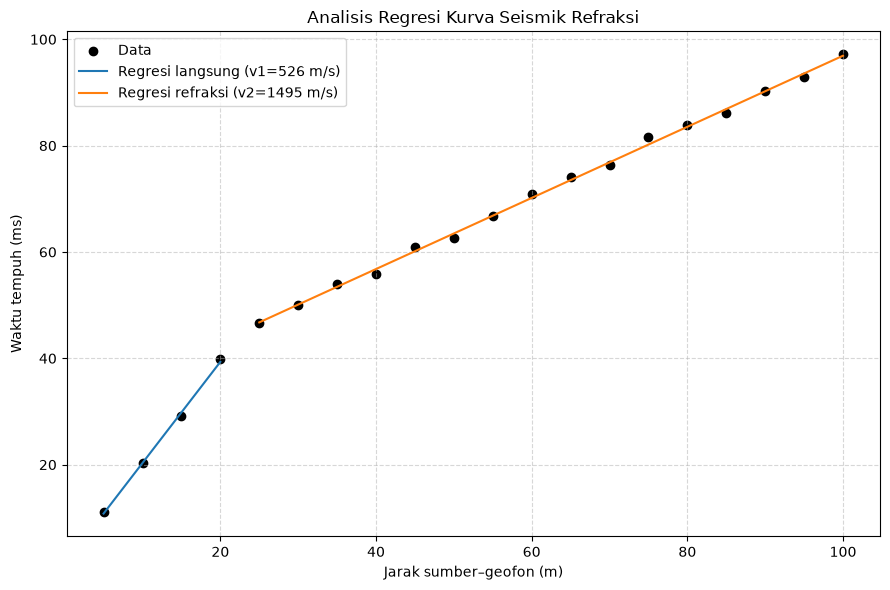

In [ ]:
plt.figure(figsize=(9, 6))
plt.scatter(df["Distance_m"], df["Time_ms"], color="black", label="Data")
x1 = np.linspace(direct["Distance_m"].min(), direct["Distance_m"].max(), 100)
x2 = np.linspace(refracted["Distance_m"].min(), refracted["Distance_m"].max(), 100)
plt.plot(x1, (fit_direct.intercept + fit_direct.slope*x1)*1000,
         label=f"Regresi langsung (v1={v1:.0f} m/s)")
plt.plot(x2, (fit_refracted.intercept + fit_refracted.slope*x2)*1000,
         label=f"Regresi refraksi (v2={v2:.0f} m/s)")
plt.xlabel("Jarak sumber–geofon (m)")
plt.ylabel("Waktu tempuh (ms)")
plt.title("Analisis Regresi Kurva Seismik Refraksi")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### **11. Code — Menyimpan Hasil ke CSV**

Notebook menyimpan data masukan dan ringkasan parameter hasil analisis.

In [ ]:
df.to_csv("hasil_seismik_refraksi.csv", index=False)

summary = pd.DataFrame([{
    "data_type": "simulasi" if USE_SIMULATED_DATA else "pengukuran",
    "jumlah_titik": len(df),
    "jarak_maksimum_m": df["Distance_m"].max(),
    "v1_m_per_s": v1,
    "v2_m_per_s": v2,
    "intercept_time_ms": ti * 1000,
    "kedalaman_antarmuka_m": h_est,
    "r2_direct": fit_direct.rvalue**2,
    "r2_refracted": fit_refracted.rvalue**2
}])
summary.to_csv("ringkasan_seismik_refraksi.csv", index=False)

print("File tersimpan:")
print("- hasil_seismik_refraksi.csv")
print("- ringkasan_seismik_refraksi.csv")
display(summary)

File tersimpan:
- hasil_seismik_refraksi.csv
- ringkasan_seismik_refraksi.csv


,data_type,jumlah_titik,jarak_maksimum_m,v1_m_per_s,v2_m_per_s,intercept_time_ms,kedalaman_antarmuka_m,r2_direct,r2_refracted
0,simulasi,20,100.0,525.738386,1495.182196,30.039939,8.43523,0.997984,0.998135


### **12. Result — Hasil dan Interpretasi**

Setelah semua sel dijalankan, amati grafik waktu tempuh, nilai kecepatan hasil regresi, waktu intersep, dan estimasi kedalaman antarmuka.

- Kecepatan dihitung dari kebalikan gradien kurva waktu tempuh terhadap jarak.
- Model dua lapisan mengasumsikan kecepatan refraktor lebih tinggi daripada lapisan atas.
- Estimasi kedalaman sangat bergantung pada pemilihan segmen regresi dan kualitas data.
- Jika menggunakan data simulasi, angka yang dihasilkan hanya untuk latihan dan tidak menggambarkan kondisi geologi lokasi nyata.

### **13. Optional Check — Checklist Kualitas**

- [ ] Kolom `Distance_m` dan `Time_ms` tersedia.
- [ ] Tidak terdapat nilai kosong atau non-numerik.
- [ ] Jarak dan waktu tempuh bernilai positif.
- [ ] Data diurutkan berdasarkan jarak.
- [ ] Pemisahan segmen gelombang langsung dan refraksi diperiksa berdasarkan grafik.
- [ ] Kecepatan dan kedalaman ditafsirkan sesuai asumsi model.
- [ ] Status data simulasi atau lapangan dinyatakan dengan jelas.

### **14. Kesimpulan**

Recipe GEO-SEIS-002 menyediakan alur kerja dasar analisis seismik refraksi, mulai dari pemeriksaan data, visualisasi kurva waktu tempuh, regresi linear, estimasi kecepatan lapisan, hingga perhitungan kedalaman antarmuka dan ekspor hasil ke CSV. Hasil merupakan estimasi awal dan perlu diverifikasi dengan interpretasi geofisika yang sesuai, terutama jika diterapkan pada data lapangan.